# Single-Stock Risk Analysis Report

This notebook generates a risk report for one stock over a specified
date range, using the `ohlc_hw_cleaned` table created by the cleaning
notebook.

Adjusted closing prices are used for performance and risk metrics.
The report includes daily log returns, annualized rolling volatility,
drawdown, the Sharpe ratio, and summary statistics.

The parameters below allow the same notebook to be executed
automatically for different stocks and analysis periods.

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "TRV"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


### Loading and Validating the Requested Data

We load the selected ticker from `ohlc_hw_cleaned` using inclusive
start and end dates and a read-only database connection.

The report displays the requested period and actual observation coverage.
Prices are not extrapolated beyond the available history.

At least 21 prices are required to calculate 20 returns. Adjusted
closing prices must be finite and strictly positive, and observation
dates must be unique.

In [3]:
from pathlib import Path
from datetime import datetime
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Validate the report parameters.
if not isinstance(ticker, str) or not ticker.strip():
    raise ValueError("Ticker must be a nonempty string.")

ticker = ticker.strip().upper()

start = datetime.strptime(start_date, "%Y-%m-%d")
end = datetime.strptime(end_date, "%Y-%m-%d")

if start > end:
    raise ValueError("Start date must not be after end date.")

database_path = Path(db_path).expanduser().resolve()

if not database_path.is_file():
    raise FileNotFoundError(f"Database not found: {database_path}")

# Use SQL parameters to select the requested observations.
query = """
SELECT *
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""

with sqlite3.connect(
    database_path.as_uri() + "?mode=ro", uri=True
) as connection:
    stock_data = pd.read_sql_query(
        query,
        connection,
        params=(ticker, start_date, end_date),
        parse_dates=["ts"]
    )

if len(stock_data) < 21:
    raise ValueError(
        f"Insufficient history for {ticker}: "
        f"{len(stock_data)} prices found; at least 21 are required."
    )

if stock_data["ts"].isna().any() or stock_data["ts"].duplicated().any():
    raise ValueError("Observation dates must be valid and unique.")

prices = stock_data["adj_close"]

if not (np.isfinite(prices) & prices.gt(0)).all():
    raise ValueError("Adjusted prices must be finite and strictly positive.")

print(
    f"{ticker} from {start_date} to {end_date}: "
    f"{len(stock_data)} observed trading days"
)
print(
    "Actual coverage:",
    stock_data["ts"].min().date(),
    "to",
    stock_data["ts"].max().date()
)

display(stock_data.head())
display(stock_data.tail())

TRV from 2024-06-01 to 2024-11-30: 97 observed trading days
Actual coverage: 2024-06-03 to 2024-10-18


,ts,open,high,low,close,adj_close,volume,ticker,ticker_original,adj_close_original,...,extreme_return_flag,adj_close_reference_corrected,ohlc_repaired,extreme_return_flag_before_quarantine,expected_previous_date,return_gap_flag,raw_price_filled,raw_close_filled,volume_imputed,zero_volume_flag
0,2024-06-03,214.60,214.96,209.22,210.34,208.39,1561800,TRV,TRV,NaN,...,0,0,0,0,2024-05-31,0,0,0,0,0
1,2024-06-04,209.41,210.83,207.88,209.64,207.70,1119338,TRV,TRV,207.70,...,0,0,0,0,2024-06-03,0,0,0,0,0
2,2024-06-05,210.07,210.07,206.68,208.41,206.48,908300,TRV,TRV,206.48,...,0,0,0,0,2024-06-04,0,0,0,0,0
3,2024-06-06,209.09,210.41,208.10,209.71,207.77,935806,TRV,TRV,207.77,...,0,0,0,0,2024-06-05,0,0,0,0,0
4,2024-06-07,210.76,214.88,209.36,212.95,210.98,1295317,TRV,TRV,210.98,...,0,0,0,0,2024-06-06,0,0,0,0,0


,ts,open,high,low,close,adj_close,volume,ticker,ticker_original,adj_close_original,...,extreme_return_flag,adj_close_reference_corrected,ohlc_repaired,extreme_return_flag_before_quarantine,expected_previous_date,return_gap_flag,raw_price_filled,raw_close_filled,volume_imputed,zero_volume_flag
92,2024-10-14,236.71,240.49,235.00,240.12,240.12,1127203,TRV,TRV,240.12,...,0,0,0,0,2024-10-11,0,0,0,0,0
93,2024-10-15,242.00,243.63,240.51,240.88,240.88,1491140,TRV,TRV,240.88,...,0,0,0,0,2024-10-14,0,0,0,0,0
94,2024-10-16,242.16,243.79,240.88,242.95,242.95,969934,TRV,TRV,NaN,...,0,0,0,0,2024-10-15,0,0,0,0,0
95,2024-10-17,253.00,265.19,252.93,264.82,264.82,2847980,TRV,TRV,264.82,...,1,0,0,1,2024-10-16,0,0,0,0,0
96,2024-10-18,269.15,269.56,261.52,265.46,265.46,1225273,TRV,TRV,265.46,...,0,0,0,0,2024-10-17,0,0,0,0,0


### Risk Metrics

All metrics use adjusted closing prices.

- Daily log return: ln(price / previous_price).
- Rolling volatility: sample standard deviation of 20 daily log returns,
  annualized using sqrt(252).
- Drawdown: price / running_peak - 1. Maximum drawdown is its minimum.
- Sharpe ratio: (mean_daily_log_return × 252 - 0.02) divided by
  annualized daily-return standard deviation.

Undefined returns and rolling warm-up estimates remain missing.
Returns spanning quarantined sessions are excluded from daily-return
metrics. The 50-observation moving average requires 50 available prices.

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate log returns between successive supplied prices."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(
    returns: pd.Series, window: int = 20
) -> pd.Series:
    """Calculate annualized rolling sample volatility."""
    if window < 2:
        raise ValueError("Volatility window must be at least two.")
    return returns.rolling(
        window=window, min_periods=window
    ).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    return prices / prices.cummax() - 1


def calculate_sharpe_ratio(
    returns: pd.Series, risk_free_rate: float = 0.02
) -> float:
    """Calculate the course annualized Sharpe approximation."""
    valid_returns = returns.dropna()

    if len(valid_returns) < 2:
        return np.nan

    daily_std = valid_returns.std(ddof=1)

    if not np.isfinite(daily_std) or daily_std <= 0:
        return np.nan

    return float(
        (valid_returns.mean() * 252 - risk_free_rate)
        / (daily_std * np.sqrt(252))
    )


# Calculate adjusted-price returns and exclude known session gaps.
stock_data["log_return"] = calculate_returns(stock_data["adj_close"])

gap_mask = stock_data["return_gap_flag"].eq(1)
stock_data.loc[gap_mask, "log_return"] = np.nan

if stock_data["log_return"].notna().sum() < 20:
    raise ValueError("At least 20 eligible daily returns are required.")

stock_data["rolling_volatility"] = calculate_volatility(
    stock_data["log_return"]
)
stock_data["drawdown"] = calculate_max_drawdown(
    stock_data["adj_close"]
)
stock_data["ma_50"] = stock_data["adj_close"].rolling(
    window=50, min_periods=50
).mean()

sharpe_ratio = calculate_sharpe_ratio(stock_data["log_return"])
max_drawdown = stock_data["drawdown"].min()

print("Eligible daily log returns:",
      stock_data["log_return"].notna().sum())
print("Sharpe ratio:",
      f"{sharpe_ratio:.3f}" if np.isfinite(sharpe_ratio) else "N/A")
print(f"Maximum drawdown: {max_drawdown:.2%}")

display(
    stock_data[
        ["ts", "adj_close", "log_return",
         "rolling_volatility", "drawdown", "ma_50"]
    ].tail()
)

Eligible daily log returns: 96
Sharpe ratio: 2.251
Maximum drawdown: -7.85%


,ts,adj_close,log_return,rolling_volatility,drawdown,ma_50
92,2024-10-14,240.12,0.014852,0.212108,-0.008833,227.5540
93,2024-10-15,240.88,0.003160,0.212254,-0.005696,228.2176
94,2024-10-16,242.95,0.008557,0.212550,0.000000,228.9292
95,2024-10-17,264.82,0.086195,0.367319,0.000000,230.0564
96,2024-10-18,265.46,0.002414,0.367443,0.000000,231.1504


### Risk Visualization

The four panels show adjusted prices with a 50-observation moving
average, daily log returns, annualized 20-return rolling volatility,
and drawdown from the running peak.

Price segments are red when rolling volatility exceeds its report-period
mean, green otherwise, and gray when the estimate is unavailable.
This coloring is retrospective, not a trading signal.

Rolling warm-up estimates remain missing. The title shows the requested
period; the subtitle discloses actual data coverage.

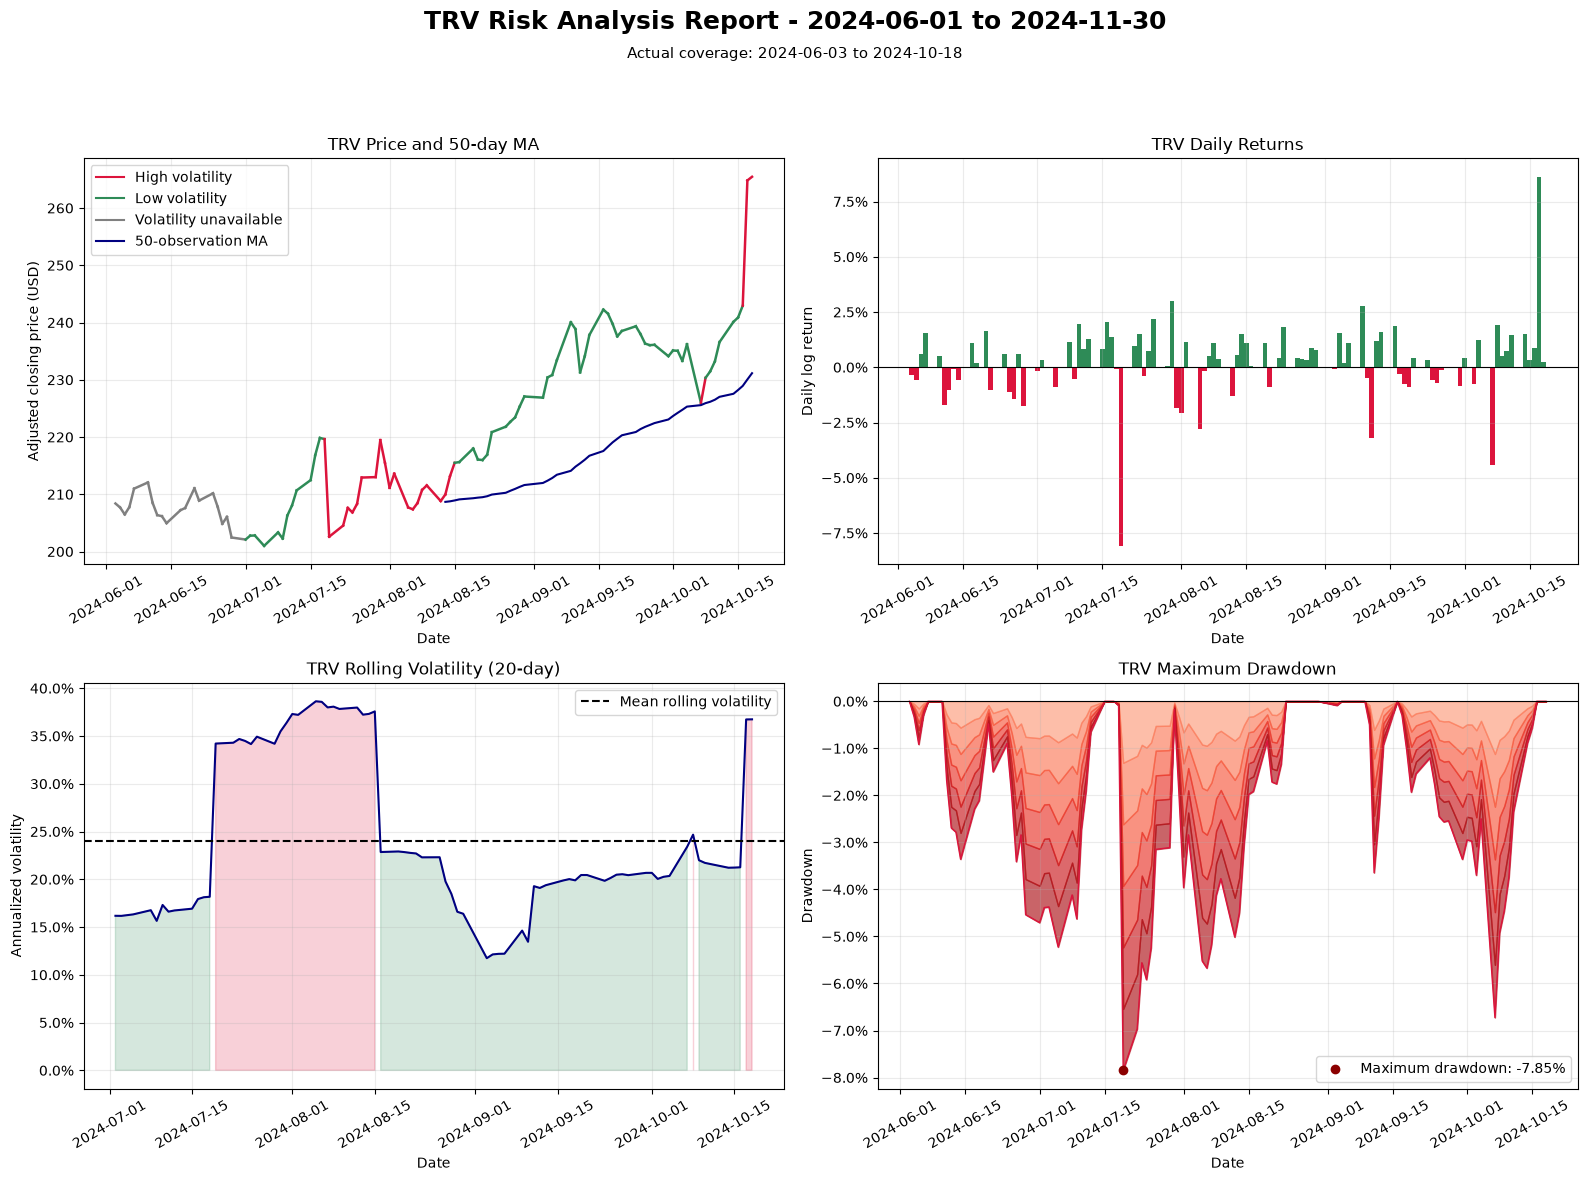

In [5]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

dates = stock_data["ts"]
adjusted_prices = stock_data["adj_close"]
returns = stock_data["log_return"]
volatility = stock_data["rolling_volatility"]
drawdown = stock_data["drawdown"]

mean_volatility = volatility.mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: color each price segment using its ending volatility estimate.
ax = axes[0, 0]

for i in range(1, len(stock_data)):
    estimate = volatility.iloc[i]
    color = (
        "gray" if pd.isna(estimate)
        else "crimson" if estimate > mean_volatility
        else "seagreen"
    )
    ax.plot(
        dates.iloc[i - 1:i + 1],
        adjusted_prices.iloc[i - 1:i + 1],
        color=color,
        linewidth=1.8
    )

ax.plot(dates, stock_data["ma_50"], color="navy", linewidth=1.5)

ax.legend(handles=[
    Line2D([0], [0], color="crimson", label="High volatility"),
    Line2D([0], [0], color="seagreen", label="Low volatility"),
    Line2D([0], [0], color="gray", label="Volatility unavailable"),
    Line2D([0], [0], color="navy", label="50-observation MA")
])
ax.set_title(f"{ticker} Price and 50-day MA")
ax.set_ylabel("Adjusted closing price (USD)")

if stock_data["ma_50"].notna().sum() == 0:
    ax.text(
        0.02, 0.95, "MA unavailable: fewer than 50 prices",
        transform=ax.transAxes, va="top"
    )

# Panel 2: daily log returns.
ax = axes[0, 1]
bar_colors = np.where(
    returns.gt(0), "seagreen",
    np.where(returns.lt(0), "crimson", "gray")
)
ax.bar(dates, returns, color=bar_colors, width=1.0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Daily Returns")
ax.set_ylabel("Daily log return")
ax.yaxis.set_major_formatter(PercentFormatter(1))

# Panel 3: annualized rolling volatility and its mean.
ax = axes[1, 0]
ax.plot(dates, volatility, color="navy", linewidth=1.5)
ax.axhline(
    mean_volatility, color="black", linestyle="--",
    label="Mean rolling volatility"
)
ax.fill_between(
    dates, 0, volatility,
    where=volatility.gt(mean_volatility),
    color="crimson", alpha=0.2
)
ax.fill_between(
    dates, 0, volatility,
    where=volatility.le(mean_volatility),
    color="seagreen", alpha=0.2
)
ax.set_title(f"{ticker} Rolling Volatility (20-day)")
ax.set_ylabel("Annualized volatility")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()

# Panel 4: layered fills create a red/pink drawdown gradient.
ax = axes[1, 1]
for layer in range(1, 7):
    ax.fill_between(
        dates, drawdown * (layer - 1) / 6,
        drawdown * layer / 6,
        color=plt.cm.Reds(0.25 + layer * 0.1),
        alpha=0.65
    )

ax.plot(dates, drawdown, color="crimson", linewidth=1)
worst_index = drawdown.idxmin()
ax.scatter(
    dates.loc[worst_index], drawdown.loc[worst_index],
    color="darkred", zorder=5,
    label=f"Maximum drawdown: {drawdown.min():.2%}"
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Maximum Drawdown")
ax.set_ylabel("Drawdown")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()

# Apply consistent formatting to all panels.
for ax in axes.flat:
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.25)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
    fontsize=18, fontweight="bold"
)
fig.text(
    0.5, 0.94,
    f"Actual coverage: {dates.min().date()} to {dates.max().date()}",
    ha="center", fontsize=11
)

fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Summary Statistics

Total return is calculated from the first and last adjusted closing
prices. Annualized return compounds eligible daily log returns using
252 trading sessions per year.

Annualized volatility uses the sample standard deviation of daily log
returns over the full observed period. It differs from the mean rolling
volatility shown in the chart.

Best/worst days and average up/down days use log returns. Positive days
are divided by all eligible returns, including zero returns. Empty
up/down subsets are displayed as N/A.

All calculations retain fractional values; percentages are formatted
only for display. Results describe actual coverage, not an extrapolation
to the requested end date.

In [6]:
# Use eligible daily log returns.
valid_returns = stock_data["log_return"].dropna()
n_returns = len(valid_returns)

up_days = valid_returns.loc[valid_returns.gt(0)]
down_days = valid_returns.loc[valid_returns.lt(0)]

total_return = (
    stock_data["adj_close"].iloc[-1]
    / stock_data["adj_close"].iloc[0]
    - 1
)

annualized_return = np.expm1(
    valid_returns.sum() * 252 / n_returns
)

annualized_volatility = valid_returns.std(ddof=1) * np.sqrt(252)

# Preserve numeric values for later automated result collection.
summary_metrics = {
    "Total Return": float(total_return),
    "Annualized Return": float(annualized_return),
    "Annualized Volatility": float(annualized_volatility),
    "Sharpe Ratio": float(sharpe_ratio),
    "Maximum Drawdown": float(stock_data["drawdown"].min()),
    "Best Day": float(valid_returns.max()),
    "Worst Day": float(valid_returns.min()),
    "Positive Days": float(valid_returns.gt(0).mean()),
    "Average Up Day": float(up_days.mean()),
    "Average Down Day": float(down_days.mean())
}


def format_metric(name, value):
    """Format summary values without changing underlying calculations."""
    if not np.isfinite(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.3f}"
    return f"{value:.2%}"


summary_table = pd.DataFrame({
    "Metric": list(summary_metrics),
    "Value": [
        format_metric(name, value)
        for name, value in summary_metrics.items()
    ]
})

print(
    f"{ticker}: {stock_data['ts'].min().date()} "
    f"to {stock_data['ts'].max().date()}"
)
display(summary_table)

TRV: 2024-06-03 to 2024-10-18


,Metric,Value
0,Total Return,27.39%
1,Annualized Return,88.78%
2,Annualized Volatility,27.34%
3,Sharpe Ratio,2.251
4,Maximum Drawdown,-7.85%
5,Best Day,8.62%
6,Worst Day,-8.08%
7,Positive Days,62.50%
8,Average Up Day,1.11%
9,Average Down Day,-1.17%


### Results for Automated Collection

The notebook exposes a named JSON output so that the batch runner can
collect each stock's results after successful execution.

Returns and volatility are stored as decimal fractions. Average volatility
is the mean of the available annualized 20-session rolling estimates.
It differs from the full-period annualized volatility shown above.

Requested dates and actual coverage are included to make incomplete
coverage explicit. Undefined numerical metrics are stored as null.

In [7]:
def finite_float_or_none(value):
    """Convert finite numeric values to floats and undefined values to null."""
    return float(value) if np.isfinite(value) else None


report_results = {
    "output_name": "stock_report_results",
    "ticker": ticker,
    "requested_start": start_date,
    "requested_end": end_date,
    "actual_start": stock_data["ts"].min().strftime("%Y-%m-%d"),
    "actual_end": stock_data["ts"].max().strftime("%Y-%m-%d"),
    "observation_count": int(len(stock_data)),
    "eligible_return_count": int(valid_returns.size),
    "avg_daily_return": finite_float_or_none(valid_returns.mean()),
    "avg_volatility": finite_float_or_none(
        stock_data["rolling_volatility"].mean()
    ),
    "max_drawdown": finite_float_or_none(
        stock_data["drawdown"].min()
    ),
    "sharpe_ratio": finite_float_or_none(sharpe_ratio),
    "total_return": finite_float_or_none(total_return),
}

# Store a structured output that the batch runner can identify by name.
display(
    {
        "application/json": report_results,
        "text/plain": repr(report_results),
    },
    raw=True,
)

{'output_name': 'stock_report_results', 'ticker': 'TRV', 'requested_start': '2024-06-01', 'requested_end': '2024-11-30', 'actual_start': '2024-06-03', 'actual_end': '2024-10-18', 'observation_count': 97, 'eligible_return_count': 96, 'avg_daily_return': 0.00252138381369852, 'avg_volatility': 0.24027368719314196, 'max_drawdown': -0.0784661572052402, 'sharpe_ratio': 2.2510189426801714, 'total_return': 0.27386150966936995}